# BBH merger-rate density from star formation and time delays

This tutorial computes the redshift evolution of the binary black hole (BBH) merger-rate density using a cosmic star-formation history, a metallicity-dependent formation efficiency, and an exponential distribution of the time between binary formation and merger. We follow the analytical formulation used in *Vitale et al., "Measuring the star formation rate with gravitational waves from binary black holes"* [arXiv:1808.00901](https://arxiv.org/abs/1808.00901).

The two main quantities are:

- **Source-frame merger-rate density:** $R_m(z)=dN/(dV_c\,dt_s)$, in $\mathrm{Gpc}^{-3}\,\mathrm{yr}^{-1}$.
- **Observer-frame differential merger rate:** $d\dot N/dz=dN/(dt_{\rm obs}\,dz)$, in $\mathrm{yr}^{-1}$ per unit redshift, integrated over the full sky.

The implementation follows the [LeR SFR and time-delay tutorial](https://github.com/hemantaph/ler/blob/main/examples/rates/.SFR_time_delay.ipynb). It uses ordinary Python variables, NumPy arrays, simple loops and two small functions. Run the cells in order, from top to bottom.

**Required packages:** `numpy`, `scipy`, `matplotlib` and `astropy`. If needed, install them in a notebook cell using `%pip install numpy scipy matplotlib astropy`.

## 1. Cosmology and redshift grid

We use the Planck18 cosmology. The cosmic age $t(z)$ decreases as redshift increases. The relation between cosmic time and redshift is

$$\frac{dt}{dz}=-\frac{1}{(1+z)H(z)}.$$

For the integration, we use its absolute value,

$$\left|\frac{dt}{dz}\right|=\frac{1}{(1+z)H(z)}.$$

The time quantities in the delay calculation are expressed in Gyr. The local merger-rate density is fixed to the illustrative value $R_0=19\,\mathrm{Gpc}^{-3}\,\mathrm{yr}^{-1}$ used in the original tutorial.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

from scipy.integrate import trapezoid, cumulative_trapezoid
from scipy.special import erf
import astropy.units as u
from astropy.cosmology import FlatLambdaCDM

cosmo = FlatLambdaCDM(
    H0=70,
    Om0=0.3,
    Ob0=0.045
)

# Redshift grid
z_max = 10
z = np.linspace(0, z_max, 500)

# Local BBH merger rate (Gpc^-3 yr^-1)
R0 = 19

# Cosmic age in Gyr
t = cosmo.age(z).to_value(u.Gyr)

# Hubble parameter in Gyr^-1
H = cosmo.H(z).to_value(1 / u.Gyr)

# Absolute value of dt/dz in Gyr
dt_dz = 1 / ((1 + z) * H)

## 2. Star-formation rate density

The Madau–Dickinson (2014) star-formation rate density is

$$\psi(z)=0.015\frac{(1+z)^{2.7}}{1+\left[(1+z)/2.9\right]^{5.6}}.$$

Its units are $M_\odot\,\mathrm{Mpc}^{-3}\,\mathrm{yr}^{-1}$. The expression is evaluated at every redshift in the array `z`.

In [21]:
# Star-formation rate (Msun Mpc^-3 yr^-1)
psi = 0.015 * (1 + z)**2.7 / (1 + ((1 + z)/2.9)**5.6)

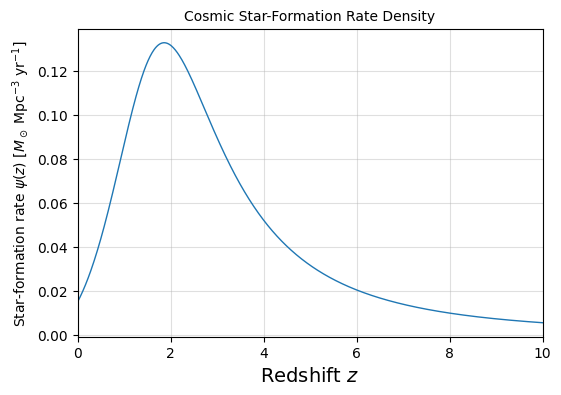

In [22]:
# plot the star-formation rate
plt.figure(figsize=(6, 4))
plt.plot(z, psi, color='C0', lw=1)
plt.xlabel('Redshift $z$', fontsize=14)
plt.ylabel('Star-formation rate $\psi(z)$ [$M_\odot$ Mpc$^{-3}$ yr$^{-1}$]', fontsize=10)
plt.title('Cosmic Star-Formation Rate Density', fontsize=10)
plt.grid(alpha=0.4)
plt.xlim(0, z_max)
plt.show()

## 3. Metallicity evolution and efficiency

We need to compute the mean metallicity evolution $Z_{\rm mean}(z)$ to evaluate the metallicity-dependent formation efficiency $\eta(z)$.

### 3.1 Mean metallicity evolution

Following the prescription of Belczynski et al. (2016),

$$
\begin{equation}
\begin{split}
\log_{10}Z_{\rm mean}(z)
=
0.5+\log_{10}\left[
\frac{y(1-R)}{\rho_b}
\int_z^{20}\psi(z')
\left|\frac{dt}{dz'}\right|dz'
\right],
\end{split}
\end{equation}
$$

where

- $y=0.019$ is the metal yield,
- $R=0.27$ is the fraction of stellar mass returned to the interstellar medium,
- $\rho_b$ is the comoving baryon mass density, given by

$$
\rho_b=2.77\times10^{11}\,\Omega_b h^2
\;M_\odot\,\mathrm{Mpc}^{-3}.
$$

Here, $h=H_0/(100\,\mathrm{km\,s^{-1}\,Mpc^{-1}})$ and $\Omega_b=0.045$.

Note that $Z_{\rm mean}(z)$ represents the absolute metallicity (metal mass fraction), not the metallicity in solar units. We adopt a solar metallicity of $Z_\odot=0.02$, following Belczynski et al. (2016).

Since the SFR is expressed per year, $|dt/dz|$ must also be expressed in years.

To evaluate the metallicity integral, we first compute the cumulative integral from $0$ to $z$ and subtract it from the total integral:

$$
\begin{equation}
\begin{split}
\int_z^{20}f(z')\,dz'
=
\int_0^{20}f(z')\,dz'
-
\int_0^z f(z')\,dz',
\end{split}
\end{equation}
$$

where

$$
f(z)=\psi(z)\left|\frac{dt}{dz}\right|.
$$

We use a separate redshift grid extending to $z=20$ for the metallicity calculation and interpolate the result onto the original redshift grid.

A small positive lower bound on the integral prevents taking the logarithm of zero.

In [23]:
# Metallicity model parameters
Omega_b = 0.045
R = 0.27
y = 0.019
h = cosmo.H0.value / 100

# Solar metallicity
Z_sun = 0.02

# Baryon density (Msun Mpc^-3)
rho_b = 2.77e11 * Omega_b * h**2

# Redshift grid for metallicity integration
z_metal = np.linspace(0, 20, 2001)

# Star-formation rate on the metallicity grid
psi_metal = (
    0.015 * (1 + z_metal)**2.7
    / (1 + ((1 + z_metal)/2.9)**5.6)
)

# Hubble parameter in yr^-1
H_metal = cosmo.H(z_metal).to_value(1 / u.yr)

# Absolute value of dt/dz in years
dt_dz_metal = 1 / ((1 + z_metal) * H_metal)

# Integral from 0 to z
integral = cumulative_trapezoid(
    psi_metal * dt_dz_metal, z_metal, initial=0
)

# Integral from z to 20
integral = integral[-1] - integral

# Interpolate onto the original redshift grid
integral = np.interp(z, z_metal, integral)

# Avoid log10(0)
integral = np.maximum(integral, 1e-40)

# Mean metallicity in logarithmic absolute units
log_Zmean = 0.5 + np.log10(y * (1 - R) * integral / rho_b)

# Mean metallicity in absolute units
Zmean = 10**log_Zmean

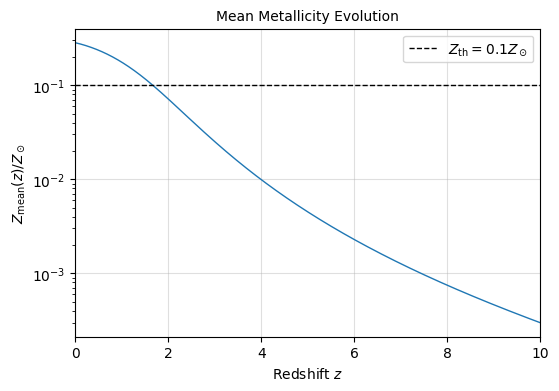

In [24]:
# Plot mean metallicity in solar units
plt.figure(figsize=(6, 4))
plt.plot(z, Zmean / Z_sun, color='C0', lw=1)

# Metallicity threshold
plt.axhline(0.1, color='k', ls='--', lw=1,
            label=r'$Z_{\rm th}=0.1Z_\odot$')

plt.xlabel('Redshift $z$', fontsize=10)
plt.ylabel(r'$Z_{\rm mean}(z)/Z_\odot$', fontsize=10)
plt.title('Mean Metallicity Evolution', fontsize=10)
plt.yscale('log')
plt.xlim(0, z_max)
plt.grid(alpha=0.4)
plt.legend()
plt.show()

### 3.2 Low-metallicity formation efficiency

Massive stellar binaries are more likely to form binary black holes in low-metallicity environments. We account for this by introducing a metallicity-dependent formation efficiency.

Following Vitale et al. (2019), assume that the logarithm of metallicity follows a normal distribution with location $\log_{10}Z_{\rm mean}(z)$ and standard deviation $\sigma_Z=0.5$ dex:

$$
\begin{equation}
\begin{split}
\log_{10}Z
\sim
\mathcal{N}\left(
\log_{10}Z_{\rm mean}(z),
\sigma_Z^2
\right).
\end{split}
\end{equation}
$$

The formation efficiency $\eta(z)$ is defined as the fraction of star formation occurring below the metallicity threshold

$$
Z_{\rm th}=0.1Z_\odot.
$$

Since $Z_\odot=0.02$, the corresponding absolute metallicity threshold is

$$
Z_{\rm th}=0.1\times0.02=0.002.
$$

The fraction of star formation below this threshold is obtained from the cumulative distribution function of the normal distribution:

$$
\begin{equation}
\begin{split}
\eta(z)
&=P(Z<Z_{\rm th})\\
&=\frac{1}{2}\left[
1+\operatorname{erf}\left(
\frac{\log_{10}Z_{\rm th}
-\log_{10}Z_{\rm mean}(z)}
{\sqrt{2}\sigma_Z}
\right)
\right].
\end{split}
\end{equation}
$$

The efficiency $\eta(z)$ lies between 0 and 1.

At higher redshifts, the mean metallicity of the Universe is lower. Consequently, a larger fraction of star formation occurs in low-metallicity environments, increasing the BBH formation efficiency.

In [25]:
# Metallicity distribution parameters
sigma_Z = 0.5
Z_th = 0.1 * Z_sun

# Fraction of low-metallicity star formation
eta = 0.5 * (1 + erf(
    (np.log10(Z_th) - log_Zmean) / (np.sqrt(2) * sigma_Z)
))

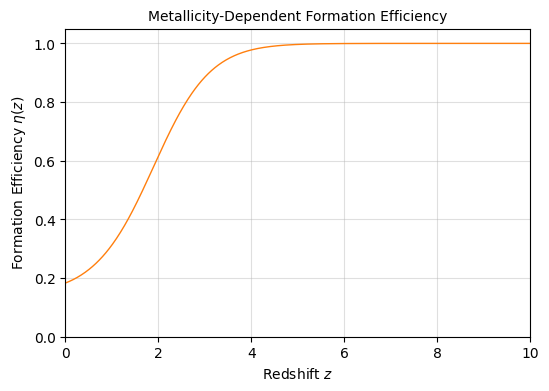

In [26]:
# Plot metallicity-dependent formation efficiency
plt.figure(figsize=(6, 4))
plt.plot(z, eta, color='C1', lw=1)
plt.xlabel('Redshift $z$', fontsize=10)
plt.ylabel(r'Formation Efficiency $\eta(z)$', fontsize=10)
plt.title('Metallicity-Dependent Formation Efficiency', fontsize=10)
plt.grid(alpha=0.4)
plt.xlim(0, z_max)
plt.ylim(0, 1.05)
plt.show()

## 4. BBH formation-rate density

The BBH formation-rate density is assumed to be proportional to the star-formation rate weighted by the metallicity efficiency:

$$R_f(z)=A\,\eta(z)\psi(z).$$

The unknown conversion factor $A$ will be fixed by normalizing the merger rate at $z=0$. For now, `Rf` represents the unnormalized formation-rate shape $\eta(z)\psi(z)$.

In [27]:
# BBH formation rate before normalization
Rf = eta * psi

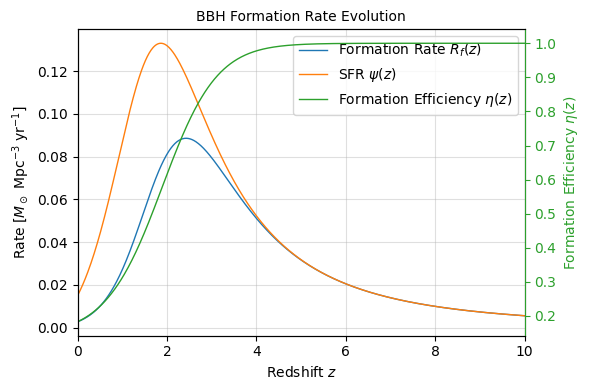

In [ ]:
# plot the BBH formation rate density evolution with SFR and metallicity-dependent formation efficiency
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(z, Rf, color='C0', lw=1, label=r'Formation Rate $R_f(z)$')
ax.plot(z, psi, color='C1', lw=1, label=r'SFR $\psi(z)$')
ax.set_xlabel('Redshift $z$', fontsize=10)
ax.set_ylabel(r'Rate [$M_\odot$ Mpc$^{-3}$ yr$^{-1}$]', fontsize=10)
ax.set_title('BBH Formation Rate Evolution', fontsize=10)
# ax.set_yscale('log')
ax.set_xlim(0, z_max)
ax.grid(alpha=0.4)

# Independent efficiency scale on the right-hand y-axis.
ax_eta = ax.twinx()
ax_eta.plot(z, eta, color='C2', lw=1, label=r'Formation Efficiency $\eta(z)$')
ax_eta.set_ylabel(r'Formation Efficiency $\eta(z)$', fontsize=10, color='C2')
ax_eta.tick_params(axis='y', colors='C2')
ax_eta.spines['right'].set_color('C2')

lines = ax.get_lines() + ax_eta.get_lines()
ax.legend(lines, [line.get_label() for line in lines])
fig.tight_layout()
plt.show()


## 5. Source-frame merger-rate density

A binary that merges at redshift $z_m$ must have formed at an earlier cosmic time, corresponding to a formation redshift $z_f\geq z_m$. Its delay time is

$$t_d=t(z_m)-t(z_f)\geq 0.$$

We assume an exponential delay-time probability density with scale $\tau>0$:

$$p(t_d\mid\tau)=\frac{1}{\tau}\exp\left(-\frac{t_d}{\tau}\right),\qquad t_d\geq 0.$$

The unnormalized merger-rate shape is

$$I(z_m;\tau)=\int_{z_m}^{z_{\max}}\eta(z_f)\psi(z_f)\,p(t_d\mid\tau)\left|\frac{dt}{dz_f}\right|dz_f.$$

Normalize this shape to the local BBH merger-rate density:

$$R_m(z_m)=R_0\frac{I(z_m;\tau)}{I(0;\tau)}.$$

In the loop below, `z[i:]` selects redshifts from the current merger redshift to the end of the grid. `trapezoid` evaluates the integral numerically. The function returns the normalized source-frame merger-rate array in $\mathrm{Gpc}^{-3}\,\mathrm{yr}^{-1}$.

In [33]:
def merger_rate(tau):

    Rm = np.zeros(len(z))

    for i in range(len(z)):

        # Formation redshifts
        zf = z[i:]

        # Time delay between formation and merger
        td = t[i] - t[i:]

        # Exponential time-delay probability density
        p_td = np.exp(-td / tau) / tau

        # Merger-rate integrand
        integrand = Rf[i:] * p_td * dt_dz[i:]

        # Integrate over formation redshift
        Rm[i] = trapezoid(integrand, zf)

    # Normalize to the local BBH merger rate
    Rm = R0 * Rm / Rm[0]

    return Rm

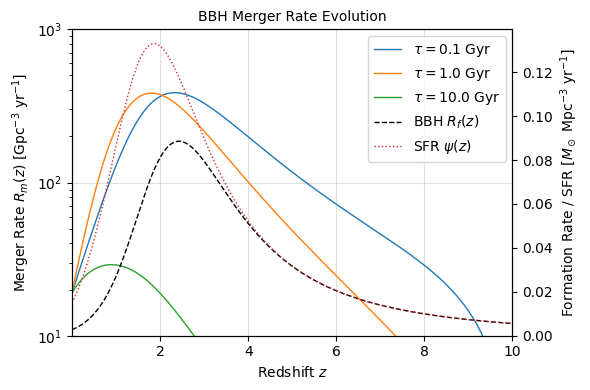

In [55]:
# plot merger rate density, formation rate density, and SFR evolution
fig, ax = plt.subplots(figsize=(6, 4))
# Time-delay parameters in Gyr
tau_values = [0.1, 1.0, 10]
# plot the merger rate density evolution for different time-delay parameters
for tau in tau_values:
    Rm = merger_rate(tau)
    ax.plot(z, Rm, lw=1, label=r'$\tau={:.1f}$ Gyr'.format(tau))
ax.set_xlabel('Redshift $z$', fontsize=10)
ax.set_ylabel(r'Merger Rate $R_m(z)$ [Gpc$^{-3}$ yr$^{-1}$]', fontsize=10)
ax.set_title('BBH Merger Rate Evolution', fontsize=10)
ax.set_xlim(0.001, z_max)
ax.set_ylim(1e1, 1e3)
ax.set_yscale('log')
ax.grid(alpha=0.4)

# Formation rate and SFR share the right-hand y-axis.
ax_rf = ax.twinx()
ax_rf.plot(z, Rf, color='k', lw=1, ls='--', label=r'BBH $R_f(z)$')
ax_rf.plot(z, psi, color='C3', lw=1, ls=':', label=r'SFR $\psi(z)$')
ax_rf.set_ylabel(r'Formation Rate / SFR [$M_\odot$ Mpc$^{-3}$ yr$^{-1}$]', fontsize=10)
ax_rf.set_ylim(bottom=0)

lines = ax.get_lines() + ax_rf.get_lines()
ax.legend(lines, [line.get_label() for line in lines])
fig.tight_layout()
plt.show()


## 6. Observer-frame differential merger rate

The source-frame volumetric merger-rate density can be converted to an all-sky rate per unit observer time and redshift:

$$\frac{d\dot N}{dz}=\frac{R_m(z)}{1+z}\frac{dV_c}{dz}.$$

The factor $(1+z)^{-1}$ accounts for cosmological time dilation. Astropy returns the differential comoving volume per steradian, so multiply by $4\pi$ to obtain the full-sky volume element.

The code uses the name `detector_frame_rate`, but this quantity is **not** the rate of detectable events; no detector selection effects have been applied.

In [56]:
# Full-sky differential comoving volume (Gpc^3 per redshift)
dVc_dz = 4 * np.pi * cosmo.differential_comoving_volume(z).to_value(
    u.Gpc**3 / u.sr
)

def detector_frame_rate(Rm):

    return Rm * dVc_dz / (1 + z)

## 7. Calculate merger rates for different time delays

Compare five values of $\tau$, measured in Gyr. For each value, compute the source-frame rate density, the observer-frame differential rate, and the total all-sky merger rate within the redshift range:

$$\dot N=\int_0^{z_{\max}}\frac{d\dot N}{dz}\,dz.$$

The calculated arrays are stored in lists for later plotting. Every source-frame curve should have the same value $R_m(0)=R_0$.

In [62]:
# Time-delay scales in Gyr
tau_list = [0.1, 1, 10]

# Store the calculated rates
source_rates = []
detector_rates = []

for tau in tau_list:

    Rm = merger_rate(tau)
    dN_dz = detector_frame_rate(Rm)

    source_rates.append(Rm)
    detector_rates.append(dN_dz)

    # Total all-sky merger rate
    total_rate = trapezoid(dN_dz, z)

    print("Time-delay scale:", tau, "Gyr")
    print("Local merger rate:", Rm[0], "Gpc^-3 yr^-1")
    print("Total merger rate:", round(total_rate), "yr^-1")
    print()

Time-delay scale: 0.1 Gyr
Local merger rate: 19.0 Gpc^-3 yr^-1
Total merger rate: 153303 yr^-1

Time-delay scale: 1 Gyr
Local merger rate: 19.0 Gpc^-3 yr^-1
Total merger rate: 138821 yr^-1

Time-delay scale: 10 Gyr
Local merger rate: 19.0 Gpc^-3 yr^-1
Total merger rate: 9554 yr^-1



## 8. Plot the source-frame merger-rate density

Compare the intrinsic redshift evolution of $R_m(z)$ for different delay timescales. Short delays tend to follow the metallicity-weighted formation history more closely, whereas longer delays shift mergers toward later cosmic times (lower redshifts).

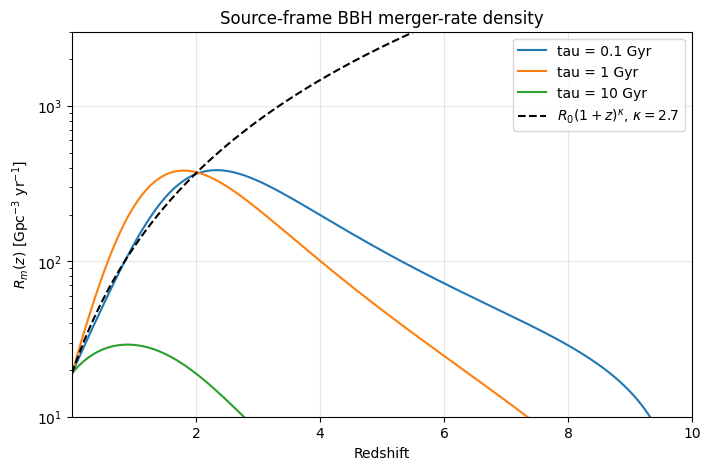

In [ ]:
plt.figure(figsize=(8, 5))

for tau, Rm in zip(tau_list, source_rates):

    plt.plot(z, Rm, label=f"tau = {tau} Gyr")

# Power-law comparison, normalized to the same local merger rate.
kappa = 2.7
plt.plot(z, R0 * (1 + z)**kappa, color='k', ls='--',
         label=rf'$R_0(1+z)^{{\kappa}}$, $\kappa={kappa}$')

plt.xlabel("Redshift")
plt.ylabel(r"$R_m(z)$ [Gpc$^{-3}$ yr$^{-1}$]")
plt.title("Source-frame BBH merger-rate density")
plt.yscale('log')
plt.ylim(1e1, 3e3)
plt.xlim(0.001, z_max)
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## 9. Plot the observer-frame differential merger rate

This plot includes the effects of the comoving volume and cosmological time dilation. Unlike the source-frame rate density, it describes the expected number of mergers per observer year per unit redshift across the full sky.

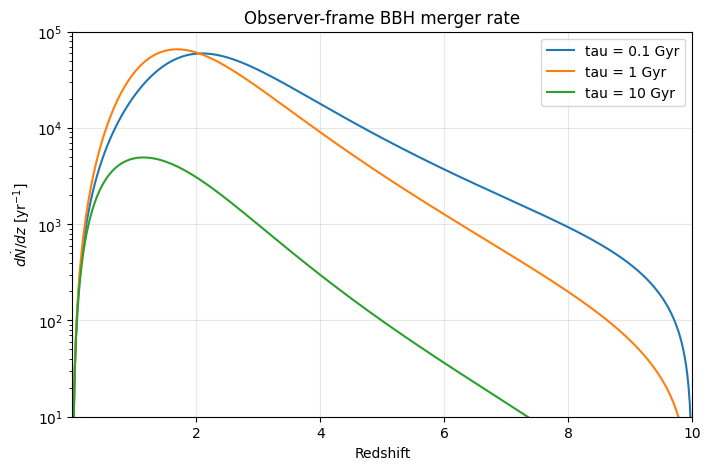

In [68]:
plt.figure(figsize=(8, 5))

for tau, dN_dz in zip(tau_list, detector_rates):

    plt.plot(z, dN_dz, label=f"tau = {tau} Gyr")

plt.xlabel("Redshift")
plt.ylabel(r"$d\dot{N}/dz$ [yr$^{-1}$]")
plt.title("Observer-frame BBH merger rate")
plt.yscale("log")
plt.yscale('log')
plt.xlim(0.001, z_max)
plt.ylim(1e1, 1e5)
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## 10. Plot the normalized redshift probability density

Dividing the observer-frame differential merger rate by the integrated rate gives the normalized merger-redshift probability density:

$$p(z)=\frac{d\dot N/dz}{\displaystyle\int_0^{z_{\max}}(d\dot N/dz')\,dz'},$$

where the denominator denotes the integral of the differential rate evaluated at $z'$. By construction, $\int_0^{z_{\max}}p(z)\,dz=1$. This distribution describes all mergers within the chosen redshift interval, without detector selection effects.

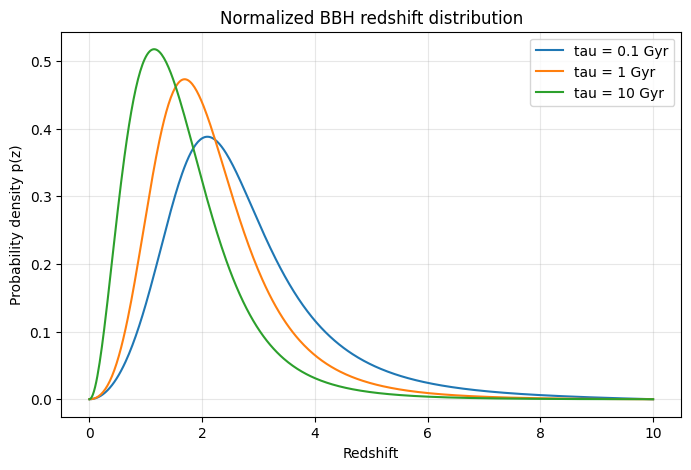

In [69]:
plt.figure(figsize=(8, 5))

for tau, dN_dz in zip(tau_list, detector_rates):

    # Normalize the redshift distribution
    p_z = dN_dz / trapezoid(dN_dz, z)

    plt.plot(z, p_z, label=f"tau = {tau} Gyr")

plt.xlabel("Redshift")
plt.ylabel("Probability density p(z)")
plt.title("Normalized BBH redshift distribution")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## Numerical and physical considerations

- **Grid resolution:** The original 700-point grid is retained for simplicity. For short delays such as $\tau=0.1$ Gyr, try 7000 points and verify convergence of the rates and their integrals.
- **Upper redshift limit:** This example retains $z_{\max}=10$ for both integrations. The metallicity prescription discussed in the original LeR tutorial uses an upper limit of 20. A finite cutoff also forces the merger rate to zero at the last grid point. Increase the integration limit and check sensitivity to the cutoff for research applications.
- **Model convention:** The metallicity formula and constants are preserved from the supplied implementation, rather than independently recalibrated against the original literature. Check its solar-metallicity convention before using it for quantitative research.
- **Selection effects:** The observer-frame rates are astrophysical all-sky rates, not expected GW detections. A detection probability must be incorporated to predict observed event counts.
- **Normalization:** The local rate is a fixed illustrative input, not a population-inference result calculated here.

### References and further reading

- [Original LeR SFR and time-delay tutorial](https://github.com/hemantaph/ler/blob/main/examples/rates/.SFR_time_delay.ipynb), including references to Madau & Dickinson (2014), Belczynski et al. (2016), and Vitale et al., *Measuring the star formation rate with gravitational waves from binary black holes*.